In [ ]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk3-task2-spills.ipynb")

# Task 2: Visualizing oil spills in NY State

## Instructions

- First, update the following cell to have a link to *your* Homework 3 GitHub repository:

**UPDATE THIS LINK**
https://github.com/nberry18/eds220-hwk3.git


- Review the [complete rubric for this task](https://docs.google.com/document/d/1Ce4EO3MEHW5uLks4x8BECWlkim2bcmxB4f8Qo4z26z8/edit?usp=sharing) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- Comment mindfully in a way that enriches your code. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.


## About the data
In this task you will use two datasets:

### First dataset: oil spills data

The first dataset contains information about [spilling incidents in the state of New York](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk). Make sure you study the data portal and understand what each row represents before starting to code. 
You will find extra information and metadata for this dataset in the `NYSDEC_SpillIncidents_Overview.pdf` and `NYSDEC_SpillIncidents_DataDictionary.pdf` documents available at the portal.

### Second dataset: TIGER shapefile

The second dataset is the [2026 Counties (and equivalent) TIGER shapefile](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) (file `tl_2026_us_county.zip`) from the Census Bureau. You can check the [metadata for all the TIGER shapefiles here](https://www.census.gov/programs-surveys/geography/technical-documentation/complete-technical-documentation/tiger-geo-line.html). 

### COMPLETE WORKFLOW
You will use the next code cell to complete the last exercise in the task. Leave it blank for now.

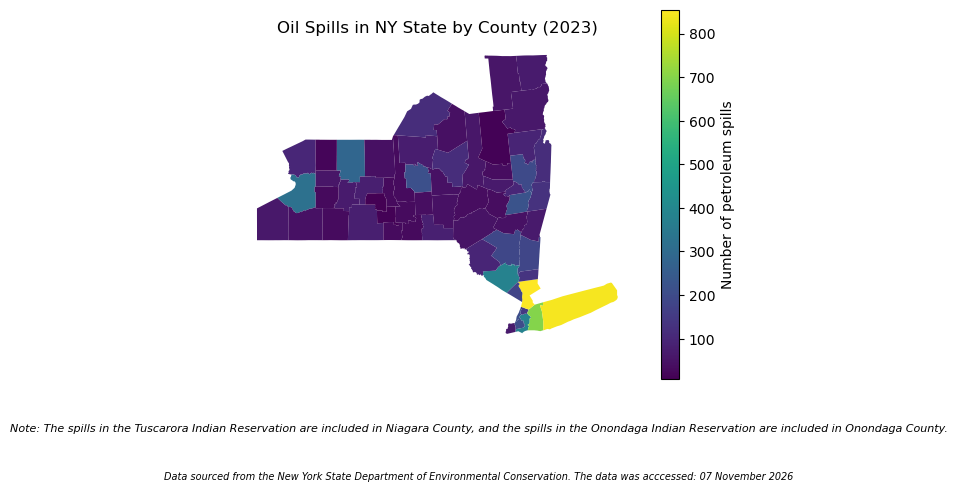

In [6]:
# FINAL CODE

# Libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

# Data
fp = os.path.join('data', 'Spill_Incidents_20261107.csv')
spills = pd.read_csv(fp)

fp = os.path.join('data','tl_2026_us_county (2)', 'tl_2026_us_county.shp')
counties = gpd.read_file(fp)

# Data Cleaning
spills.columns = spills.columns.str.strip().str.lower().str.replace(' ', '_')
spills['spill_date'] = pd.to_datetime(spills['spill_date'])

counties.columns = counties.columns.str.lower()
counties['statefp'] = counties['statefp'].astype(int)

# Data Selection
petr_23 = spills[
    (spills['spill_date'] >= '2023-01-01') & 
    (spills['spill_date'] <= '2023-12-31') & 
    (spills['material_family'] == 'Petroleum')]

spills_per_county = (petr_23.groupby('county')
                    .nunique()['spill_number']
                    .reset_index()
                    .rename(columns = {'spill_number':'n_spills'}))

ny_counties = counties[counties['statefp'] == 36]

spills_counties = spills_per_county['county'].unique()

ny_diff_counties = ny_counties['name'].unique()

ny_counties = ny_counties.rename(columns = {'name': 'county'})

# Merge
ny_spills = pd.merge(ny_counties, 
                     spills_per_county,
                     how = 'inner',
                     on = 'county')

spills_per_county['county'] = spills_per_county['county'].replace({ # replace() is for values inside of columns
'Tuscarora Indian Reservation': 'Niagara',
'Onondaga Indian Reservation': 'Onondaga'
})

# Niagara and Onondaga now appear twice (their own spills plus the reservation spills),so group rows by county 
# and add their spill counts into a single row per county
spills_per_county = spills_per_county.groupby('county').sum().reset_index()

# Remerge spills_per_county and ny_counties

ny_spills = pd.merge(ny_counties,
    spills_per_county,
    how = 'inner',
    on = 'county')

# Map
fig, ax = plt.subplots()

#Create a choropleth map of ny_spills

ny_spills.plot(ax = ax, 
                   column = 'n_spills', # this parameter indicates which column to color by
                    legend = True,
                    legend_kwds = {'label': 'Number of petroleum spills'},
                    cmap = 'viridis'
                    )

ax.axis('off')

ax.set_title('Oil Spills in NY State by County (2023)', fontsize = 12)

plt.figtext(0.5, 0.0, 'Note: The spills in the Tuscarora Indian Reservation are included in Niagara County, and the spills in the Onondaga Indian Reservation are included in Onondaga County.',
    ha = 'center', fontsize = 8, style = 'italic')

plt.figtext(0.5, -0.10, 'Data sourced from the New York State Department of Environmental Conservation. The data was acccessed: 07 November 2026',
    ha = 'center', fontsize = 7, style = 'italic')

plt.show()

## 1. File management
a. Any data you download should go in the `data/` folder of your `eds220-hwk3` repository. For example, after downloading both datasets, your repository should look like this:

```
eds220-hwk3/
├── data/
│   ├── q5d_df.csv
│   ├── Spill_Incidents_20261027.csv
│   └── tl_2026_us_county/
│       ├── tl_2026_us_county.cpg
│       ├── tl_2026_us_county.dbf
│       ├── tl_2026_us_county.prj
│       ├── tl_2026_us_county.shp
│       └── ... (other files from the shapefile)
├── tests/
├── .gitignore
├── LICENSE
├── README.md
└── hwk3-task2-spills.ipynb
```

The date in the name of the spills file may be different, depending on when you download it. `data/q5d_df.csv` is already in the repository and is used by the autograder tests, so do not delete or move it.

**IMPORTANT: Do not commit your data!**

The datasets we'll be working with are large and will most likely jam your commit history if git does not ignore them.

b. Add the relative path of each dataset you downloaded to your `.gitignore` file. For example, to ignore the folder containing the shapefile, add `data/tl_2026_us_county/` to the `.gitignore`.

c. Commit and push your changes to the `.gitignore`.

d. Run `git status` and verify that none of your data is being tracked by git.

## 2. Datasets description
- Read the metadata for both datasets and write a brief description about each one. Indicate the data sources and date of access.

## 3. Import libraries

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## 4. Import data 
In the next cell:

- Import the NY spills data as a variable named `spills`. 
- Import the US counties data as a variable named `counties`.

If you are using file paths to access the data, these should be constructed using the `os` package.

In [3]:
fp = os.path.join('data', 'Spill_Incidents_20261107.csv')
spills = pd.read_csv(fp)


fp = os.path.join('data','tl_2026_us_county (2)', 'tl_2026_us_county.shp')
counties = gpd.read_file(fp)

<!-- BEGIN QUESTION -->

## 5. Prepare spills data

This section refers to the `spills` dataframe. 
Check the outputs carefully, they will give you information you will need to use in the next exercises.

### 5.A. Exploration

In the next cells:

a. Check the dataframe's head

b. Check the data types of the columns

c. Check the unique values in the `material_family` column

d. Check the unique values in the `county` column

e. Insert a markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells for preliminary data exploration.

_Type your answer here, replacing this text._

In [4]:
#a. Check the dataframe's head
print(spills.head())
print(counties.head())

   Spill Number Program Facility Name                  Street 1 Street 2  \
0        107132                MH 864        RT 119/MILLWOOD RD      NaN   
1        405586             BOWRY BAY        WATER POLL CONTROL      NaN   
2        405586             BOWRY BAY        WATER POLL CONTROL      NaN   
3        204667            POLE 16091       GRACE AVE/BURKE AVE      NaN   
4        210559               POLE ON  FERDALE LOMIS RD / RT 52      NaN   

   Locality       County ZIP Code  SWIS Code  DEC Region  Spill Date  \
0  ELMSFORD  Westchester      NaN       6000           3  10/10/2001   
1    QUEENS       Queens      NaN       4101           2  08/21/2004   
2    QUEENS       Queens      NaN       4101           2  08/21/2004   
3     BRONX        Bronx      NaN        301           2  08/02/2002   
4   LIBERTY     Sullivan      NaN       5336           3  01/20/2003   

  Received Date Contributing Factor   Waterbody                 Source  \
0    10/10/2001             Unknown 

In [ ]:
#b. Check the data types of the columns
print(spills.dtypes)
print(counties.dtypes)

In [ ]:
#c. Check the unique values in the `material_family` column
spills["Material Family"].unique()

In [ ]:
#d. Check the unique values in the `county` column
spills["County"].unique()

In [ ]:
spills['Spill Number'].nunique()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.B. Cleaning
a. Simplify column names as needed.

In [ ]:
spills.columns = spills.columns.str.strip().str.lower().str.replace(' ', '_')

spills.columns

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Update column data types as needed.

In [ ]:
spills['spill_date'] = pd.to_datetime(spills['spill_date'])
spills['spill_date']

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.C. Data selection

a. Select data about petroleum spills that took place between January 1 and December 31, 2023 (including both dates). Store it in a variable named `petr_23`. The data selection should occur in a single line. You may add cells as needed.

In [ ]:
petr_23 = spills[
    (spills['spill_date'] >= '2023-01-01') & 
    (spills['spill_date'] <= '2023-12-31') & 
    (spills['material_family'] == 'Petroleum')]

petr_23

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use `print()` and f-strings to print a message verifying that `petr_23` only has data for 2023 and from January through December.
HINT: if you converted the `spill_date` column to datetime, you can use `petr_23['spill_date'].dt.year.unique()`.

In [ ]:
print(f"petr_23 includes data from {petr_23['spill_date'].dt.year.unique()}.")
print(f"petr_23 includes data from {petr_23['spill_date'].dt.month.unique()} months in 2023.")

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Write tests using `assert` to verify that `petr_23` only has data for petroleum spills.

In [ ]:
assert petr_23['material_family'].nunique() == 1

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Use `print()` and f-strings to print the number of rows in `petr_23` and the number of unique spills (use the `spill_number` column). Are these numbers the same? In the next markdown cell, explain why this might be the case. Use complete sentences. You may use additional cells to explore the data if needed.

_Type your answer here, replacing this text._

<!-- END QUESTION -->

### 5.D. Data aggregation

Create new dataframe named `spills_per_county` with the number of petroleum spills per county from January to December 2023.

As you found in exercise 5.C.d, a spill can appear in more than one row. Make sure you count each spill only once. HINT: `nunique()`.

The resulting `spills_per_county` dataframe must be as follows:

- Index: integer numbers starting from 0
- Two columns only.
- Column one: county names, column name = `county`
- Column two: number of petroleum spills per county in 2023, column name = `n_spills`

You may add cells if needed for your data wrangling.

In [ ]:
spills_per_county = (petr_23.groupby('county')
                    .nunique()['spill_number']
                    .reset_index()
                    .rename(columns = {'spill_number':'n_spills'}))

spills_per_county

In [ ]:
grader.check("q5d")

<!-- BEGIN QUESTION -->

## 6. Prepare counties data

This section refers to the `counties` geo-dataframe. 
Check the outputs carefully, they will give you context about the next exercises.

### 6.A. Exploration

In the next cells:

a. Check the geo-dataframe's head

b. Check the data types of the columns

c. Check the geo-dataframe's CRS

d. Plot the geo-dataframe

e. Use the next markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells of preliminary data exploration.

_Type your answer here, replacing this text._

In [ ]:
# a 
counties.head()

In [ ]:
# b
counties.dtypes

In [ ]:
# c
counties.crs

In [ ]:
# d
fig, ax = plt.subplots()

# Add pigs point plot to our figure's axes
counties.plot(ax=ax, # Add plot to specific axes
              alpha = 0.5, # Control frequency
              color = 'brown') # Update point color

# Display
plt.show()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.B. Cleaning

Simplify column names as needed.

In [ ]:
counties.columns = counties.columns.str.lower()
counties['statefp'] = counties['statefp'].astype(int)

In [ ]:
counties['statefp'] 

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.C. Data selection

Select all the counties for the state of New York in a new variable `ny_counties` and plot them (you may need to look at the metadata).

In [ ]:
ny_counties = counties[counties['statefp'] == 36]

ny_counties.plot()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 7 Merging

The goal of this section is to create a single dataframe with the number of spills per county and the corresponding geometries for each county.

### 7.A. Explore data

In the next cells:

a. Print the names of counties in `ny_counties`, without repetition.


In [ ]:
ny_diff_counties = ny_counties['name'].unique()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Print the names of counties in `spills_per_county`, without repetition. Examine the differences in the outputs.

In [ ]:
spills_counties = spills_per_county['county'].unique()

<!-- END QUESTION -->



c. Which are the county names that are in `spills_per_county`, but not in `ny_counties`? Your answer should be a list of strings
HINT: You can use the `numpy` function [`setdiff1d()`](https://numpy.org/doc/stable/reference/generated/numpy.setdiff1d.html), pay attention to the example in the documentation. Store your answer in the `diff_names` variable. 


In [ ]:
diff_names_spills = np.setdiff1d(spills_counties, ny_diff_counties)
diff_names_spills

In [ ]:
grader.check("7Ac")

d. Which are the county names that are in `ny_counties`, but not in `spills_per_county`? Your answer should be a list of a string/strings.


In [ ]:
diff_names_ny = np.setdiff1d(ny_diff_counties, spills_counties)
diff_names_ny

In [ ]:
grader.check("7Ad")

e. What is the number of spills in 'Tuscarora Indian Reservation' and in 'Onondaga Indian Reservation'?


In [ ]:
# e. 
print(spills_per_county[(spills_per_county['county']=='Tuscarora Indian Reservation')])
print(spills_per_county[(spills_per_county['county']=='Onondaga Indian Reservation')])

### 7.B. Data updates

In the next cell, update 'St Lawrence' to 'St. Lawrence' in the `spills_per_county` data frame. Verify the update was successful with an assert test. 


In [ ]:
spills_per_county[spills_per_county['county'] == 'St Lawrence']

spills_per_county['county'] = spills_per_county['county'].replace({'St Lawrence': 'St. Lawrence'})

spills_per_county[spills_per_county['county'].str.contains("St. Lawrence")]

assert spills_per_county.loc[52, 'county'] == "St. Lawrence", f"The update was not successful, the county name is {spills_per_countyloc[52, 'county']}"

### 7.C. Merge

In the following cells:

a. Use this cell to make any other updates needed for making an inner join of the `spills_per_county` and `ny_counties`. HINT: [`pd.merge`](https://pandas.pydata.org/pandas-docs/version/2.3/reference/api/pandas.merge.html)


In [ ]:
# a 
common_columns = set(ny_counties.columns).intersection(spills_per_county.columns)

if len(common_columns) != 0:
    print(f"Common columns: {common_columns}")
else: 
    print("No common columns")

In [ ]:
ny_counties = ny_counties.rename(columns = {'name': 'county'})

common_columns = set(ny_counties.columns).intersection(spills_per_county.columns)

if len(common_columns) != 0:
    print(f"Common columns: {common_columns}")
else: 
    print("No common columns")

b. Store the inner join of the `spills_per_county` and `ny_counties` dataframes in a new variable named `ny_spills`.


In [ ]:
ny_spills = pd.merge(ny_counties, 
                     spills_per_county,
                     how = 'inner',
                     on = 'county')

ny_spills

<!-- BEGIN QUESTION -->

c. An inner join only keeps the rows whose `county` appears in both dataframes, and it does not warn you about the rows it drops. Which records from `spills_per_county` were dropped by the inner join, and how many spills did each one have? Add the cells you need to find the dropped records.

In [ ]:
print(f"Counties in spills_per_county: {len(spills_per_county)}")
print(f"Countries in ny_spills: {len(ny_spills)}")

removed_counties = spills_per_county[~spills_per_county['county'].isin(ny_counties['county'])] 
removed_counties

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Does dropping these records affect the map or the information we will report? Write your answer in the following markdown cell.

_Type your answer here, replacing this text._

<!-- END QUESTION -->


From our previous exploration we know that Tuscarora Indian Reservation and Onondaga Indian Reservation will not be in the join. Tuscarora Indian Reservation is located within Niagara county and Onondaga Indian Reservation is located within Onondaga county. 

e. Since the reservations do not appear in the `ny_counties` dataframe, add the Tuscarora Indian Reservation spills to Niagara county and the Onondaga Indian Reservation spills to Onondaga county in `ny_spills`. We will add a note about this in our final map, and we will reflect on this choice in exercise 8.b. Add the cells you need to make this update **and** verify that the dataframe was updated.

In [ ]:
spills_per_county['county'] = spills_per_county['county'].replace({ # replace() is for values inside of columns
'Tuscarora Indian Reservation': 'Niagara',
'Onondaga Indian Reservation': 'Onondaga'
})

# Niagara and Onondaga now appear twice (their own spills plus the reservation spills),so group rows by county 
# and add their spill counts into a single row per county
spills_per_county = spills_per_county.groupby('county').sum().reset_index()

# Remerge spills_per_county and ny_counties

ny_spills = pd.merge(ny_counties,
    spills_per_county,
    how = 'inner',
    on = 'county')

ny_spills

## 8. Map
a. Create a choropleth map of the number of petroleum spills per county in the state of New York in 2023. 
Your map should be polished and have (at least) the following updates:
- a legend indicating the number of spills
- an updated color map
- a title 
- no axis
- an annotation with the data source (New York State Department of Environmental Conservation) and date of access



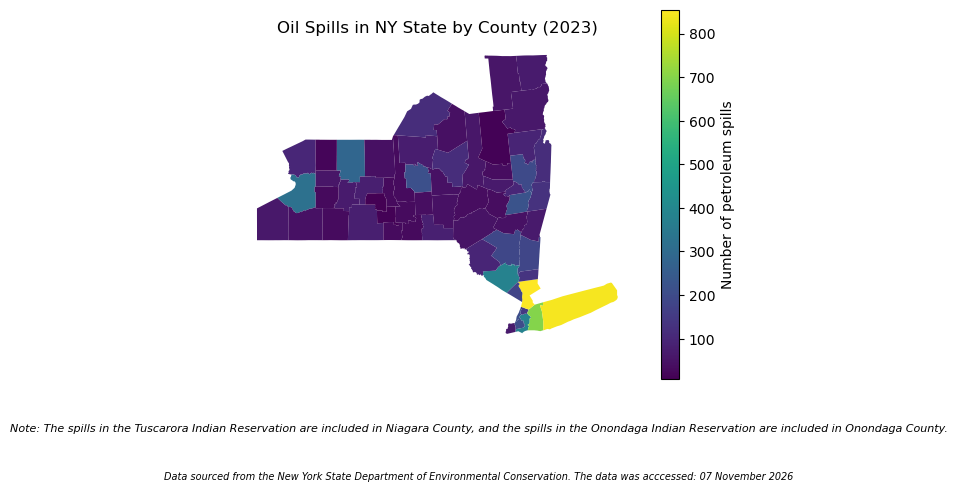

In [7]:
fig, ax = plt.subplots()

#Create a choropleth map of ny_spills

ny_spills.plot(ax = ax, 
                   column = 'n_spills', # this parameter indicates which column to color by
                    legend = True,
                    legend_kwds = {'label': 'Number of petroleum spills'},
                    cmap = 'viridis'
                    )

ax.axis('off')

ax.set_title('Oil Spills in NY State by County (2023)', fontsize = 12)

plt.figtext(0.5, 0.0, 'Note: The spills in the Tuscarora Indian Reservation are included in Niagara County, and the spills in the Onondaga Indian Reservation are included in Onondaga County.',
    ha = 'center', fontsize = 8, style = 'italic')

plt.figtext(0.5, -0.10, 'Data sourced from the New York State Department of Environmental Conservation. The data was acccessed: 07 November 2026',
    ha = 'center', fontsize = 7, style = 'italic')

plt.show()

b. Write a description of how the map was created, including key takeaways. If you need to do additional data analysis to include relevant information from the data, you may include additional cells here.

In your description, also reflect on how we handled the spills reported in the Tuscarora and Onondaga Indian Reservations (exercise 7.C.e) in terms of data governance and the CARE Principles for Indigenous Data Governance from Task 1.

## Complete workflow

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the choropleth map of the number of petroleum spills per county in the state of New York in 2023. The only output of this cell should be the choropleth map  you produced in the previous exercise. Further guidance on what to include in this final workflow is in the assignment rubric.